# Page: the main parts of a Godot editor plugin

Two kinds of class. **Extend**: you write a script and Godot calls it (blue, yellow). **Ask**: it already exists and you call it (green).

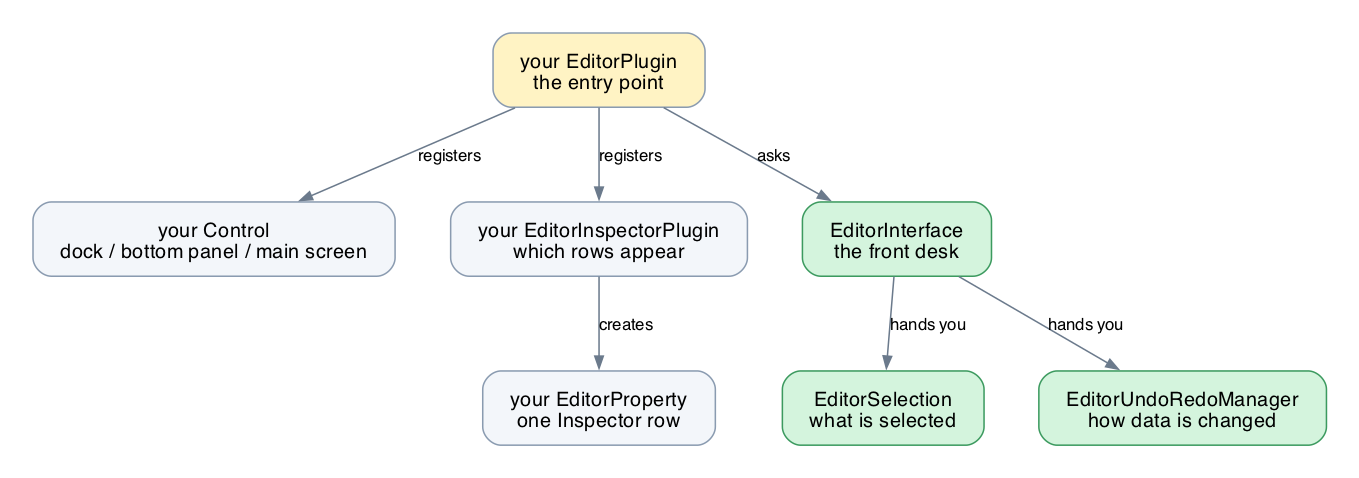

<details><summary>diagram source (graphviz)</summary>

```dot
digraph {
  rankdir=TB;
  plugin [label="your EditorPlugin\nthe entry point", fillcolor="#fff3c4"];
  dock [label="your Control\ndock / bottom panel / main screen"];
  insp [label="your EditorInspectorPlugin\nwhich rows appear"];
  prop [label="your EditorProperty\none Inspector row"];
  iface [label="EditorInterface\nthe front desk", fillcolor="#d4f4dd", color="#3c9a5f"];
  sel [label="EditorSelection\nwhat is selected", fillcolor="#d4f4dd", color="#3c9a5f"];
  undo [label="EditorUndoRedoManager\nhow data is changed", fillcolor="#d4f4dd", color="#3c9a5f"];
  plugin -> dock [label="registers"];
  plugin -> insp [label="registers"];
  insp -> prop [label="creates"];
  plugin -> iface [label="asks"];
  iface -> sel [label="hands you"];
  iface -> undo [label="hands you"];
}
```

</details>

| Class | Kind | What it is | Key functions | In the RPGM plugin |
|---|---|---|---|---|
| `EditorPlugin` | extend | Entry point; registers and unregisters everything | `_enter_tree`, `_exit_tree`, `add_control_to_bottom_panel`, `add_inspector_plugin`, `_has_main_screen` | `plugin.gd` |
| your `Control` | extend | Any UI you add: dock, bottom panel, main screen | plain Control code, or a `.tscn` | bottom dock, lambda queue editor scene |
| `EditorInterface` | ask | Front desk to every editor service | `get_selection`, `get_editor_undo_redo`, `get_editor_theme`, `get_editor_scale`, `popup_create_dialog` | every file; "Add" opens its Create dialog |
| `EditorSelection` | ask + connect | What is selected in the Scene tree | `get_selected_nodes`, signal `selection_changed` | bottom dock decides what to show |
| `EditorUndoRedoManager` | ask + connect | The right way to change scene data | `create_action`, `add_do_property`, `add_undo_property`, `commit_action`, signal `history_changed` | lambda queue editor: every add, move, delete |
| `EditorInspectorPlugin` | extend | Decides which Inspector rows appear | `_can_handle`, `_parse_begin`, `_parse_property`, `add_property_editor`, `add_custom_control` | the two files in `_rpgm_plugin_inspector/` |
| `EditorProperty` | extend | One Inspector row for one property | `_update_property`, `get_edited_object`, `get_edited_property`, `set_bottom_editor`, `emit_changed` | read-only lambda queue row |
| `EditorInspector` | ask, or create | An Inspector panel you can put anywhere | `EditorInspector.new()`, `edit(object)` | the popup that edits one lambda's values |
| `EditorFileSystem` | ask + connect | The editor's view of `res://` | `scan`, signal `filesystem_changed` | not used |
| `EditorSettings` | ask | The user's editor preferences | `get_setting`, `set_setting` | not used |
| `EditorScript` | extend | One-off script, run with File > Run | `_run`, `get_scene` | not used |

**Reading order in the plugin:** `plugin.gd` (what gets registered) → `_rpgm_plugin_script_inspector.gd` (a row is swapped) → `_rpgm_plugin_lambda_queue_editor.gd` (selection in, undo actions out).
